# Final particle spatial distribution
Analyze `particles.bin` from `test.cpp`. Each record contains three native-endian 64-bit floats `(x, y, z)` in pc, without a header. Run this notebook from the simulation directory.

The simulation uses independent fixed-length isotropic steps plus vertical drift. At large step counts, its distribution approaches a Gaussian with mean $(0,0,v_zT)$ and coordinate variance $N_{steps}\ell^2/3=2DT$, where $D=\ell^2/(6\Delta t)$. The step length is a diffusion-model parameter rather than an exponentially sampled scattering mean free path.


In [1]:
from pathlib import Path
import re
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

plt.rcParams.update({'figure.dpi': 120, 'axes.grid': False})
DATA_FILE = Path('particles.bin')
SOURCE_FILE = Path('test.cpp')

# Read current source values. These are not stored in the binary: ensure the
# simulation has been rerun after changing test.cpp, or set overrides below.
source = SOURCE_FILE.read_text()
def parameter(name):
    match = re.search(r'\b' + re.escape(name) + r'\s*=\s*([0-9.eE+\-]+)\s*;', source)
    if match is None:
        raise ValueError(f'Cannot read {name}; set the parameters manually.')
    return float(match.group(1))

N_STEPS = int(parameter('N_steps'))
EXPECTED_PARTICLES = int(parameter('N_particles'))
STEP_PC = parameter('l_scatter')
DT_YR = parameter('dt')
VZ_PC_YR = parameter('v_z')
# Optional overrides for the run that actually produced particles.bin:
# VZ_PC_YR = 3e-4

if N_STEPS <= 0 or STEP_PC <= 0 or DT_YR <= 0:
    raise ValueError('Step count, step length and timestep must be positive.')
T_YR = N_STEPS * DT_YR
D_PC2_YR = STEP_PC**2 / (6 * DT_YR)
SIGMA_PC = np.sqrt(N_STEPS * STEP_PC**2 / 3)
EXPECTED_MEAN = np.array([0., 0., VZ_PC_YR * T_YR])
print(f'T = {T_YR:g} yr; D = {D_PC2_YR:.5g} pc²/yr; sigma = {SIGMA_PC:.2f} pc')
print('Expected mean (pc):', EXPECTED_MEAN)


T = 160000 yr; D = 1.0417 pc²/yr; sigma = 577.35 pc
Expected mean (pc): [   0.    0. 4800.]


In [2]:
if not DATA_FILE.exists():
    raise FileNotFoundError(f'{DATA_FILE.resolve()} not found; run test.cpp first.')
record_bytes = 3 * np.dtype('=f8').itemsize
if DATA_FILE.stat().st_size == 0 or DATA_FILE.stat().st_size % record_bytes:
    raise ValueError('Binary size must be a nonzero multiple of 24 bytes.')
positions = np.fromfile(DATA_FILE, dtype='=f8').reshape(-1, 3)
if not np.isfinite(positions).all():
    raise ValueError('Positions contain non-finite values.')
n = len(positions)
if n < 2:
    raise ValueError('At least two particles are required for sample statistics.')
if n != EXPECTED_PARTICLES:
    print(f'WARNING: binary has {n} particles; source specifies {EXPECTED_PARTICLES}.')
mean = positions.mean(axis=0)
std = positions.std(axis=0, ddof=1)
cov = np.cov(positions, rowvar=False)
mean_se = SIGMA_PC / np.sqrt(n)
mean_scores = (mean - EXPECTED_MEAN) / mean_se
print(f'Loaded {n:,} particles ({DATA_FILE.stat().st_size:,} bytes)')
print('axis   mean [pc]   expected [pc]   std [pc]   mean discrepancy [SE]')
for j, axis in enumerate('xyz'):
    print(f'{axis:>4} {mean[j]:11.3f} {EXPECTED_MEAN[j]:15.3f} {std[j]:10.3f} {mean_scores[j]:23.2f}')
print('Sample covariance [pc²]:\n', cov)
print('Sample correlation:\n', np.corrcoef(positions, rowvar=False))
if np.any(np.abs(mean_scores) > 5):
    print('WARNING: mean differs by more than 5 theoretical standard errors. '
          'Check whether binary and source parameters match; the binary has no run metadata.')


Loaded 10,000 particles (240,000 bytes)
axis   mean [pc]   expected [pc]   std [pc]   mean discrepancy [SE]
   x     -10.422           0.000    571.354                   -1.81
   y       2.258           0.000    577.307                    0.39
   z    4801.295        4800.000    579.293                    0.22
Sample covariance [pc²]:
 [[326445.76523373  -3258.83608383  -2120.99758643]
 [ -3258.83608383 333283.12223173   1032.34187303]
 [ -2120.99758643   1032.34187303 335580.94185049]]
Sample correlation:
 [[ 1.         -0.00987985 -0.0064082 ]
 [-0.00987985  1.          0.00308687]
 [-0.0064082   0.00308687  1.        ]]


## Coordinate distributions
Histograms are normalized probability densities. Curves show the large-step Gaussian prediction using the source parameters, without fitting to the data.


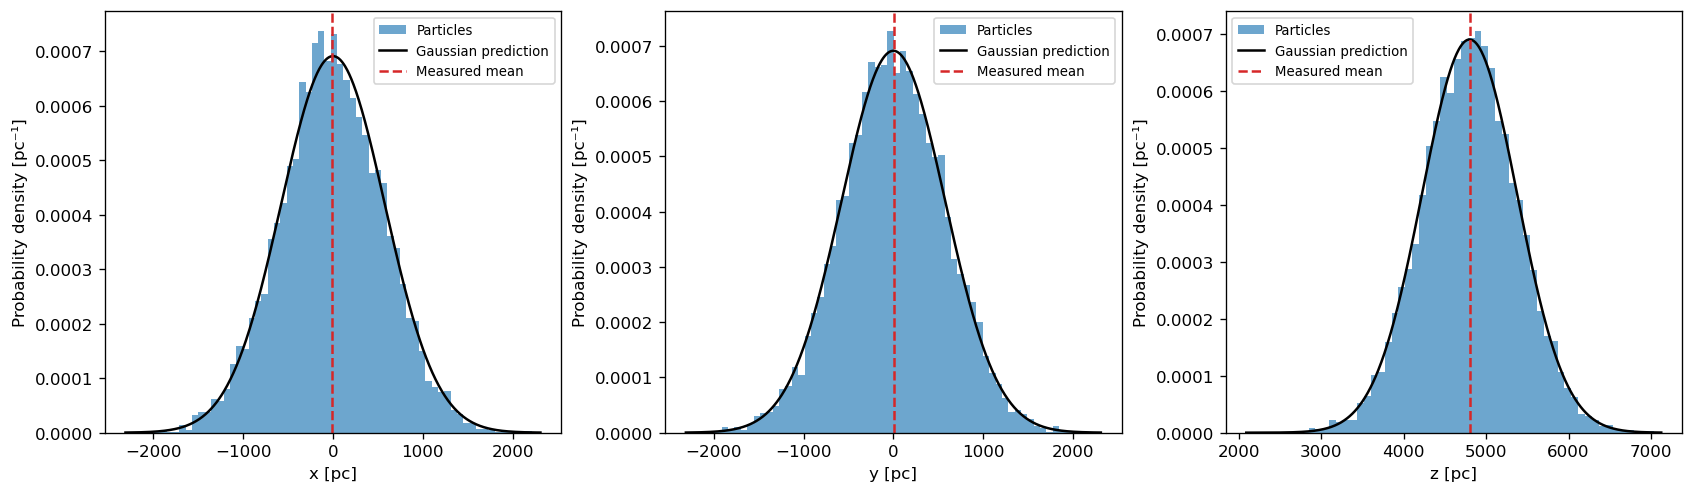

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
for j, ax in enumerate(axes):
    values = positions[:, j]
    ax.hist(values, bins=60, density=True, alpha=0.65, label='Particles')
    lo = min(values.min(), EXPECTED_MEAN[j] - 4 * SIGMA_PC)
    hi = max(values.max(), EXPECTED_MEAN[j] + 4 * SIGMA_PC)
    grid = np.linspace(lo, hi, 800)
    density = np.exp(-0.5 * ((grid - EXPECTED_MEAN[j]) / SIGMA_PC)**2) / (np.sqrt(2*np.pi) * SIGMA_PC)
    ax.plot(grid, density, 'k-', label='Gaussian prediction')
    ax.axvline(mean[j], color='tab:red', linestyle='--', label='Measured mean')
    ax.set(xlabel=f'{"xyz"[j]} [pc]', ylabel='Probability density [pc⁻¹]')
    ax.legend(fontsize=8)
plt.show()


## Spatial projections
Logarithmic color scales display particles per bin. All plots have equal spatial aspect ratios and show the measured and predicted centers.


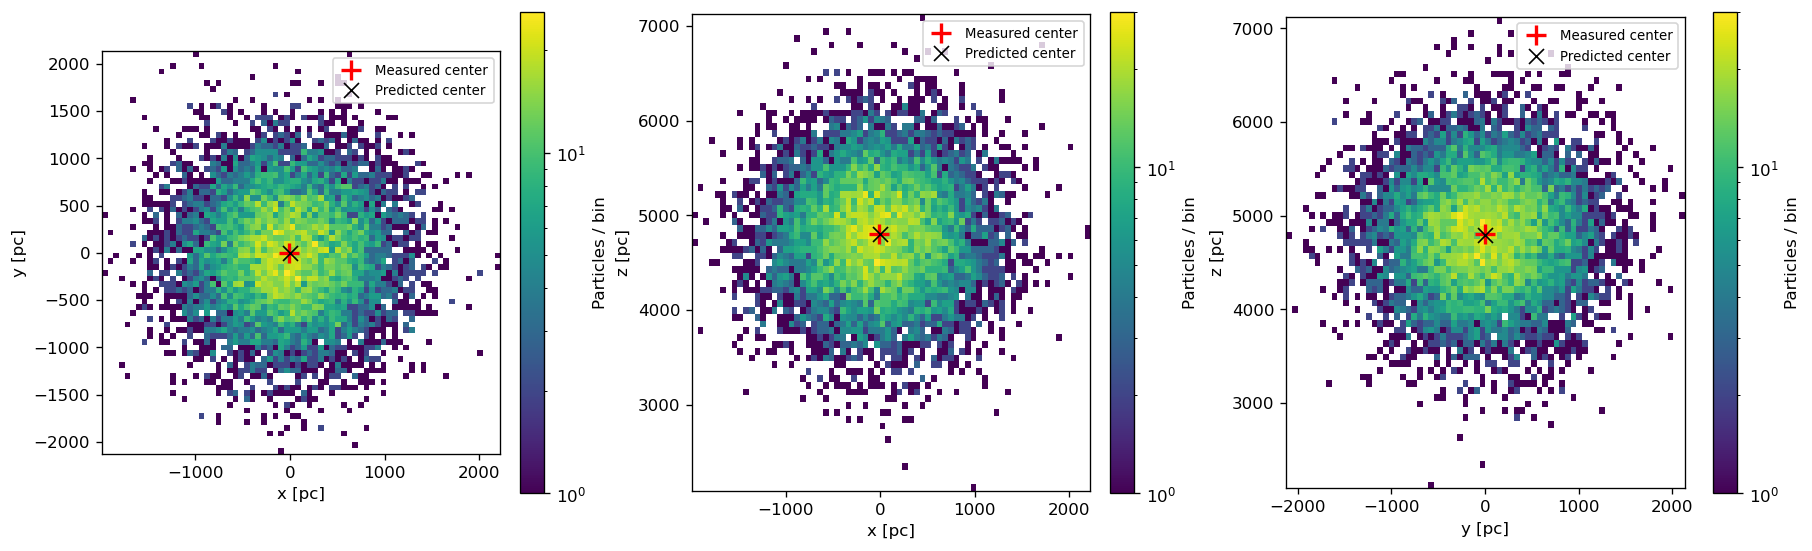

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)
for ax, (a, b) in zip(axes, [(0, 1), (0, 2), (1, 2)]):
    hist = ax.hist2d(positions[:, a], positions[:, b], bins=70, norm=LogNorm(), cmin=1)
    ax.plot(mean[a], mean[b], 'r+', ms=12, mew=2, label='Measured center')
    ax.plot(EXPECTED_MEAN[a], EXPECTED_MEAN[b], 'kx', ms=9, label='Predicted center')
    ax.set(xlabel=f'{"xyz"[a]} [pc]', ylabel=f'{"xyz"[b]} [pc]', aspect='equal')
    ax.legend(fontsize=8)
    fig.colorbar(hist[3], ax=ax, label='Particles / bin')
plt.show()


## Three-dimensional view
A reproducible subset of at most 3,000 particles is shown to keep the plot readable. Statistics above use every particle.


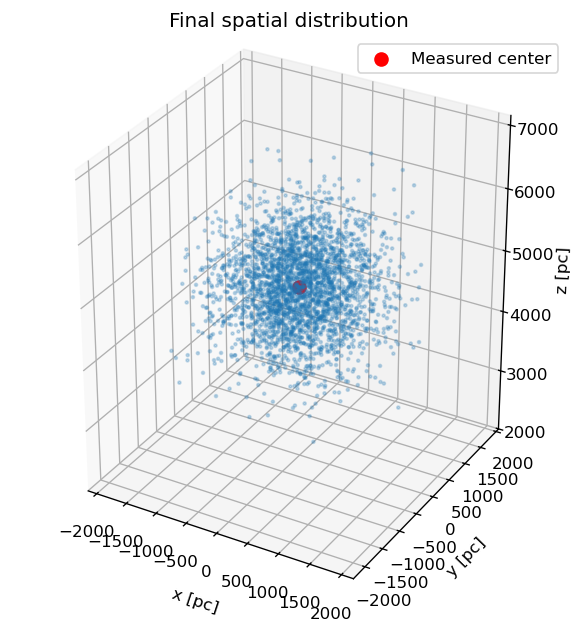

In [5]:
indices = np.random.default_rng(12345).choice(n, size=min(n, 3000), replace=False)
p = positions[indices]
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(p[:, 0], p[:, 1], p[:, 2], s=3, alpha=0.25)
ax.scatter(*mean, color='red', s=60, label='Measured center')
ax.set(xlabel='x [pc]', ylabel='y [pc]', zlabel='z [pc]', title='Final spatial distribution')
ax.set_box_aspect(np.maximum(np.ptp(p, axis=0), 1e-12))
ax.legend()
plt.show()


## Distance from the drifting center
The distance $r=|\mathbf{x}-\mathbf{v}T|$ follows approximately a Maxwell distribution, with expected RMS radius $\sqrt{3}\sigma$. Centering uses the **predicted** drift, so stale parameters remain visible. For a density per unit volume, divide radial shell counts by shell volume rather than plotting a radial probability density.


Measured RMS radius: 997.660 pc
Expected RMS radius: 1000.000 pc
Measured radius percentiles [pc] (50, 68, 95): [ 883.98876022 1074.90172412 1619.27266281]


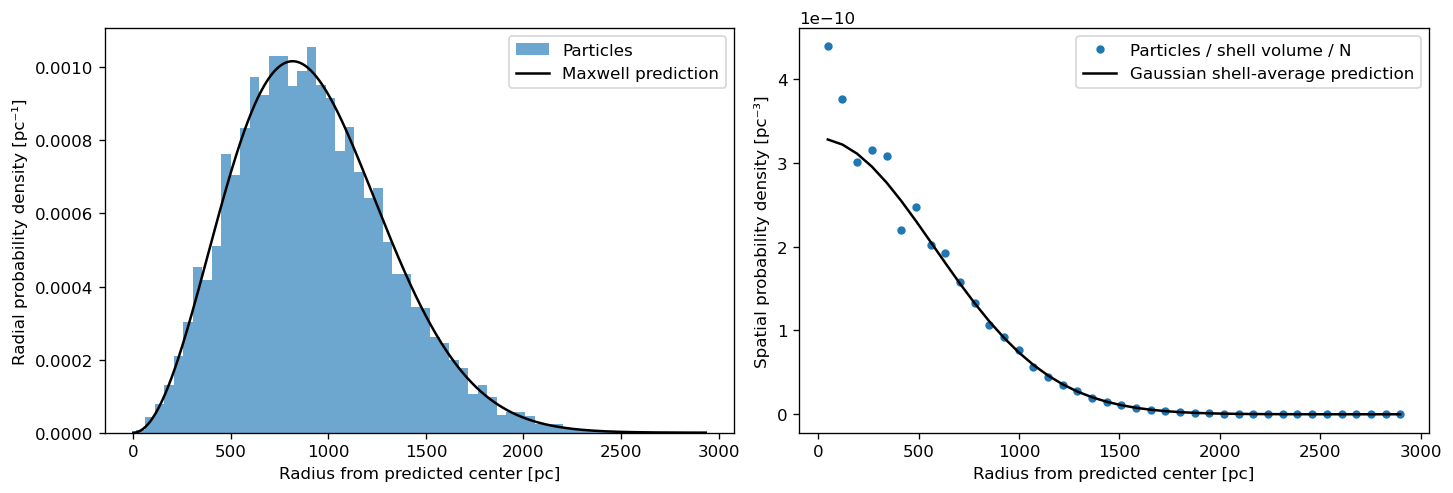

In [6]:
r = np.linalg.norm(positions - EXPECTED_MEAN, axis=1)
print(f'Measured RMS radius: {np.sqrt(np.mean(r**2)):.3f} pc')
print(f'Expected RMS radius: {np.sqrt(3) * SIGMA_PC:.3f} pc')
print('Measured radius percentiles [pc] (50, 68, 95):', np.percentile(r, [50, 68, 95]))
grid = np.linspace(0, max(r.max(), 5 * SIGMA_PC), 800)
maxwell = np.sqrt(2 / np.pi) * grid**2 / SIGMA_PC**3 * np.exp(-grid**2 / (2 * SIGMA_PC**2))
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
axes[0].hist(r, bins=60, density=True, alpha=0.65, label='Particles')
axes[0].plot(grid, maxwell, 'k-', label='Maxwell prediction')
axes[0].set(xlabel='Radius from predicted center [pc]', ylabel='Radial probability density [pc⁻¹]')
axes[0].legend()
counts, edges = np.histogram(r, bins=40)
volumes = (4 * np.pi / 3) * (edges[1:]**3 - edges[:-1]**3)
centers = (edges[1:] + edges[:-1]) / 2
axes[1].plot(centers, counts / (n * volumes), 'o', ms=4, label='Particles / shell volume / N')
# Average theoretical volume density over each shell using the Maxwell CDF.
from math import erf
u = edges / SIGMA_PC
cdf = np.array([erf(value / np.sqrt(2)) for value in u]) - np.sqrt(2 / np.pi) * u * np.exp(-u**2 / 2)
axes[1].plot(centers, np.diff(cdf) / volumes, 'k-', label='Gaussian shell-average prediction')
axes[1].set(xlabel='Radius from predicted center [pc]', ylabel='Spatial probability density [pc⁻³]')
axes[1].legend()
plt.show()
